### First let's load needed packages

In [1]:
!pip install git+https://github.com/Kalharap/py-recon.git

  Cloning https://github.com/Kalharap/py-recon.git to /private/var/folders/h6/knrmk8bn0gldks9wrt_fpth00000gn/T/pip-req-build-q2_s0jjp
  Running command git clone --filter=blob:none --quiet https://github.com/Kalharap/py-recon.git /private/var/folders/h6/knrmk8bn0gldks9wrt_fpth00000gn/T/pip-req-build-q2_s0jjp
  Resolved https://github.com/Kalharap/py-recon.git to commit aeacf575c02221239fff36962853f13f557f1ba3
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import pyrecon
import pandas as pd
import numpy as np

### Let's upload chronologies and observed values as dataframes

In [3]:
# 1) Load the chronologies as a DataFrame (year-indexed)
df = pd.read_excel('Data/chrons_residual.xlsx', header=0, index_col=0)

# 2) Load the observed gauge values as a series
nf = pd.read_excel('Data/guage data.xlsx', header=2, index_col=0)
nf = nf.iloc[:, 0]

#  Stepwise Regression

## 1) First we need to choose the best set of chronologies using stepwise selection


=== Best subset (sequential selection) ===
Direction: forward
Number of chrons : 8
Best chrons: ['DJM', 'DOU', 'PUM', 'RED', 'RIF', 'SAR', 'TRG', 'WIL']
CV neg-MSE: -6729104.0333 ± 1884005.2328


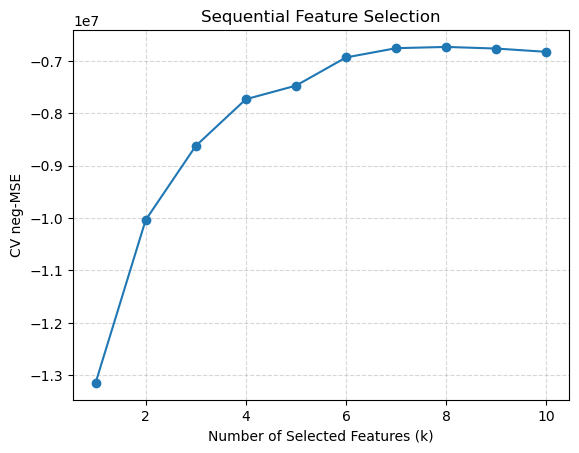

In [4]:
number_of_chrons, best_chrons, best_score, best_std, results = pyrecon.find_best_set_of_chrons(
    df, nf,10, 1906, 1995,direction="forward", plot=True)

## 2) Then we fit the model to the best-selected chronologies and plot.

In-sample R² : 0.8124
Cross-validated R² : 0.7373 ± 0.0980


<AxesSubplot:title={'center':'Observed vs Stepwise_Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (AF)'>

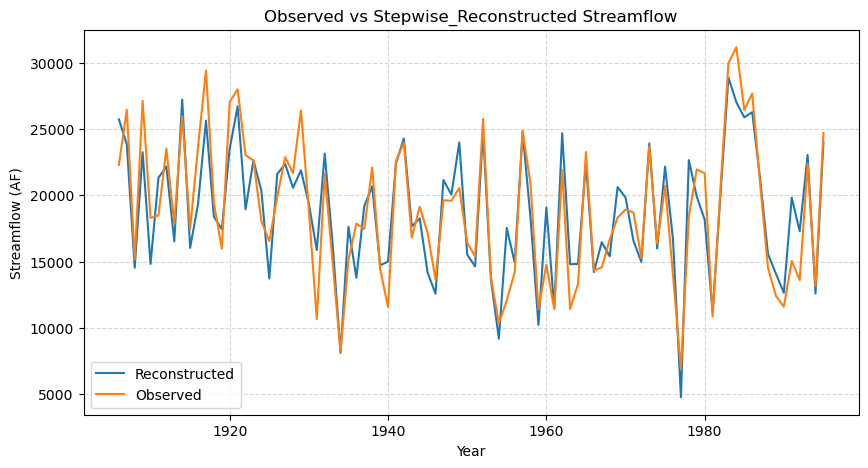

In [5]:
pipe, recon, r2_in, cv_scores= pyrecon.observed_vs_stepwise_regression(df, best_chrons, nf, 1906, 1995)

pyrecon.plot_observed_vs_reconstructed(recon, nf,1906,1995, ylabel='Streamflow (AF)',
                               xlabel='Year',title ='Observed vs Stepwise_Reconstructed Streamflow')

## 3) Then we apply the selected chronologies over the full period and run the reconstruction.

<AxesSubplot:title={'center':'Stepwise Regression Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (AF)'>

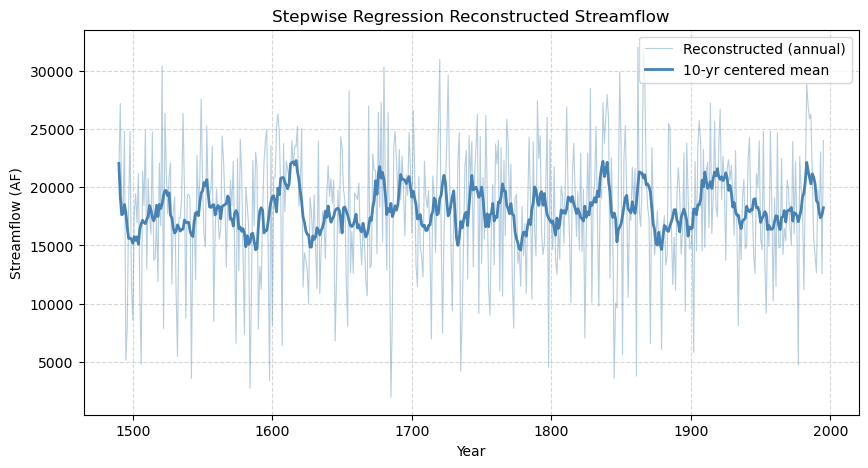

In [6]:
sr_recon = pyrecon.stepwise_regression_reconstruction(df, best_chrons, 1490, 1995, pipe)

pyrecon.plot_full_reconstruction(sr_recon, 1490, 1995,
                             smooth=True, smooth_years=10,
                             ylabel='Streamflow (AF)', xlabel='Year',
                             title='Stepwise Regression Reconstructed Streamflow')

# PCA Regression

## 1) First we need to choose the best set of PCAs

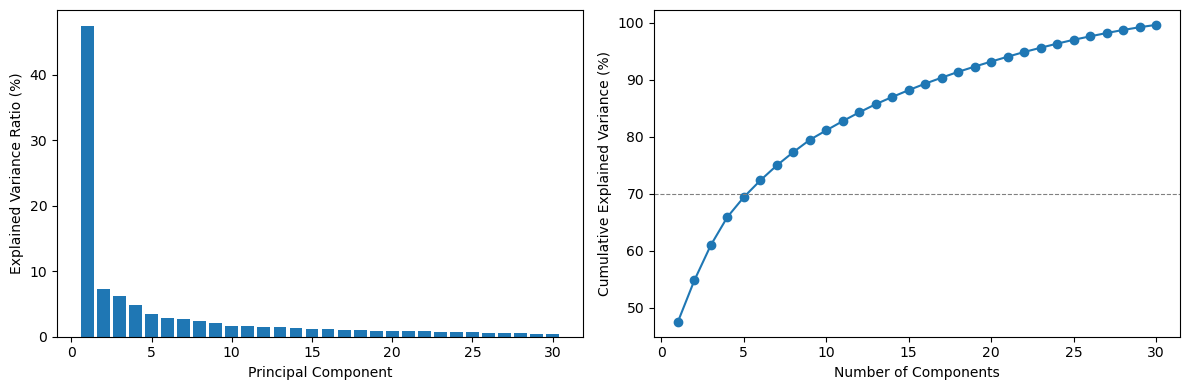

In [7]:
scaler, pca, scores, loadings, variance, cum_var, fig, axes=pyrecon.find_best_set_of_PCA(df, 30, 1490, 1995, 
                                                                                 70, plot =True)

## 2) Then we fit the model to the best-selected PCAs and plot.

In-sample R² (first 1 PCs): 0.7207
Cross-validated R² (first 1 PCs): 0.6824 ± 0.1116


<AxesSubplot:title={'center':'Observed vs PCA_Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (AF)'>

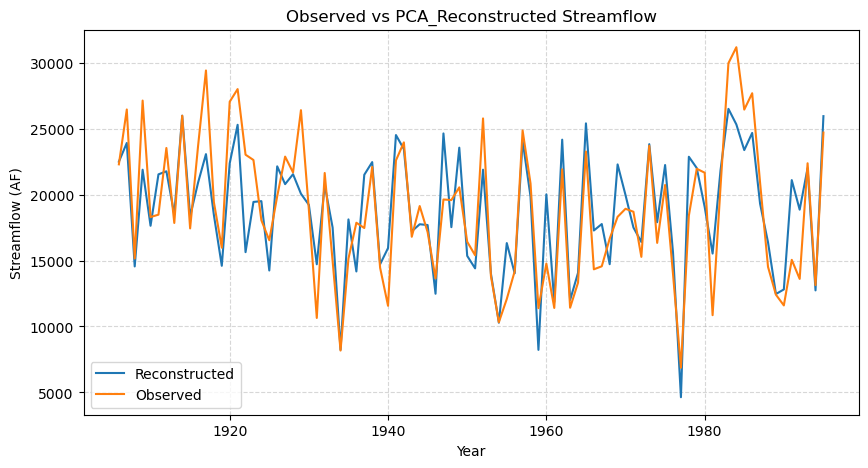

In [8]:
pipe, recon, r2_in, cv_scores = pyrecon.observed_vs_pca_regression(scores, nf, 1, 1906, 1995)

pyrecon.plot_observed_vs_reconstructed(recon, nf,1906,1995, ylabel='Streamflow (AF)',
                               xlabel='Year',title ='Observed vs PCA_Reconstructed Streamflow')

## 3) Then we apply the selected PCAs over the full period and run the reconstruction.

<AxesSubplot:title={'center':'PCA Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (AF)'>

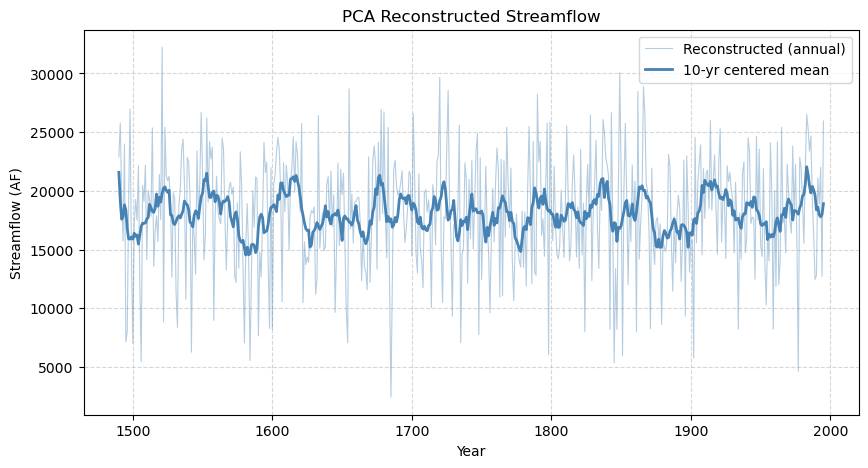

In [9]:
pca_recon = pyrecon.pca_regression_reconstruction(scores, 1, 1490, 1995, pipe)

pyrecon.plot_full_reconstruction(pca_recon, 1490, 1995,
                             smooth=True, smooth_years=10,
                             ylabel='Streamflow (AF)', xlabel='Year',
                             title='PCA Reconstructed Streamflow')

# KNN Regression

## 1) First let's fit to the claibration period and get the Leave-one out cross validation score

Leave-One-Out Cross-Validation (LOOCV) R² : 0.5814
Leave-One-Out Cross-Validation (LOOCV) RMSE : 3430.5480


<AxesSubplot:title={'center':'Observed vs KNN_Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (AF)'>

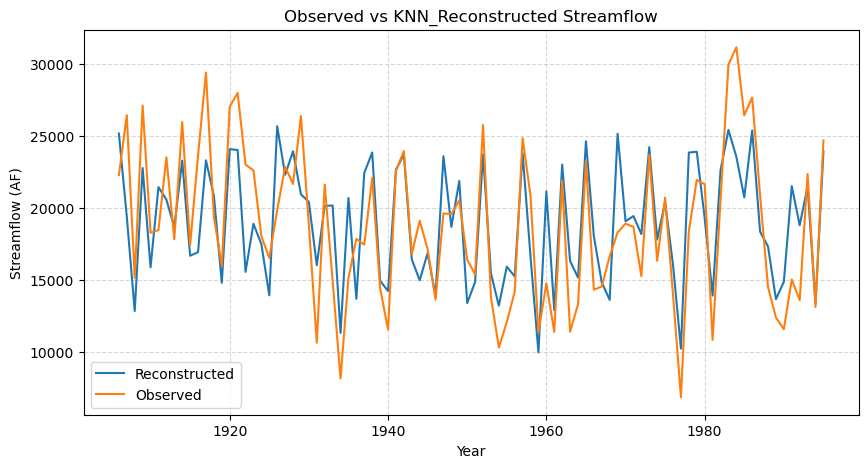

In [10]:
y_hat,r2,rmse = pyrecon.loocv_knn_mean(scores, nf, 30, 1906, 1995, k=9, weight_scheme="bisquare")

pyrecon.plot_observed_vs_reconstructed(y_hat, nf,1906,1995, ylabel='Streamflow (AF)',
                               xlabel='Year',title ='Observed vs KNN_Reconstructed Streamflow')

## 2) Then let's do the full reconstruction with knn regresison

<AxesSubplot:title={'center':'KNN Reconstructed Streamflow'}, xlabel='Year', ylabel='Streamflow (AF)'>

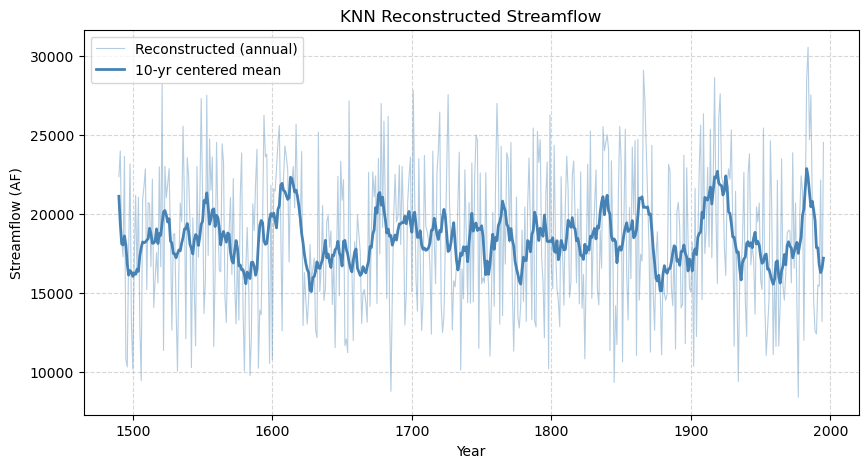

In [11]:
knn_recon, ensembles, idx, dist = pyrecon.knn_reconstruct(
    scores, nf, 30,
    calib_start=1906, calib_end=1995,
    recon_start=1490, recon_end=1995,
    k=9, weight_scheme="bisquare", ensemble_size=200
)

pyrecon.plot_full_reconstruction(knn_recon, 1490, 1995,
                             smooth=True, smooth_years=10,
                             ylabel='Streamflow (AF)', xlabel='Year',
                             title='KNN Reconstructed Streamflow')

# Finally we can use reconstruction_stat option to find the stats we need

In [12]:
summary = pd.concat([
    pyrecon.reconstruction_stats(sr_recon, 1490, 1995, name="Stepwise"),
    pyrecon.reconstruction_stats(pca_recon,      1490, 1995, name="PCA"),
    pyrecon.reconstruction_stats(knn_recon,      1490, 1995, name="KNN"),
])
summary.round(3)

,Mean,SD,Skewness,r(1),Minimum,Maximum
Stepwise,18091.827,5604.670,-0.337,0.032,1954.878,32033.119
PCA,18113.195,4995.343,-0.316,-0.002,2430.813,32231.723
KNN,18436.491,4619.876,0.071,0.083,8408.354,30530.463
